<!--
SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
SPDX-License-Identifier: Apache-2.0
-->

# Build a visual investigation agent with Nemotron 3.5 Super VL

Your team switched its AI help desk to a cheaper model. This month, the AI bill went up 30%.

Working out why takes more than one lookup. The clues are spread across a dashboard, the help-desk database and its change
log, a scanned price list, and a two-page evaluation report. And whatever fix you choose still has to resolve about as many
customer tickets as before.

This notebook shows you how to build an agent that runs that whole investigation, powered by Nemotron 3.5 Super VL. Super VL
reads the dashboard and documents as images, decides what to check next, writes SQL and Python to test its ideas, and
finishes with a specific fix that waits for a person to approve it.

**By the end, you'll be able to:**

- **Turn a screenshot into a plan.** Give Super VL a dashboard screenshot and a short request, and watch it read the
  numbers, work out what they imply, and write the queries that test its theory.
- **Pull facts out of scanned and multi-page documents.** Let it choose which pages to open, including a price list that
  exists only as a scan, and read exact numbers from them.
- **Get a fix you can approve.** Have it find the cheapest model for each kind of ticket that still resolves nearly as many
  tickets as before (no more than 2 percentage points below the previous model in an offline test), and file that as one
  proposal for a person to approve.

You can apply the same pattern wherever the answer is split between a dashboard and a stack of documents: a cloud bill that
jumped after a deploy, a budget that doesn't match the invoices, or a support team whose resolution rate suddenly dropped.

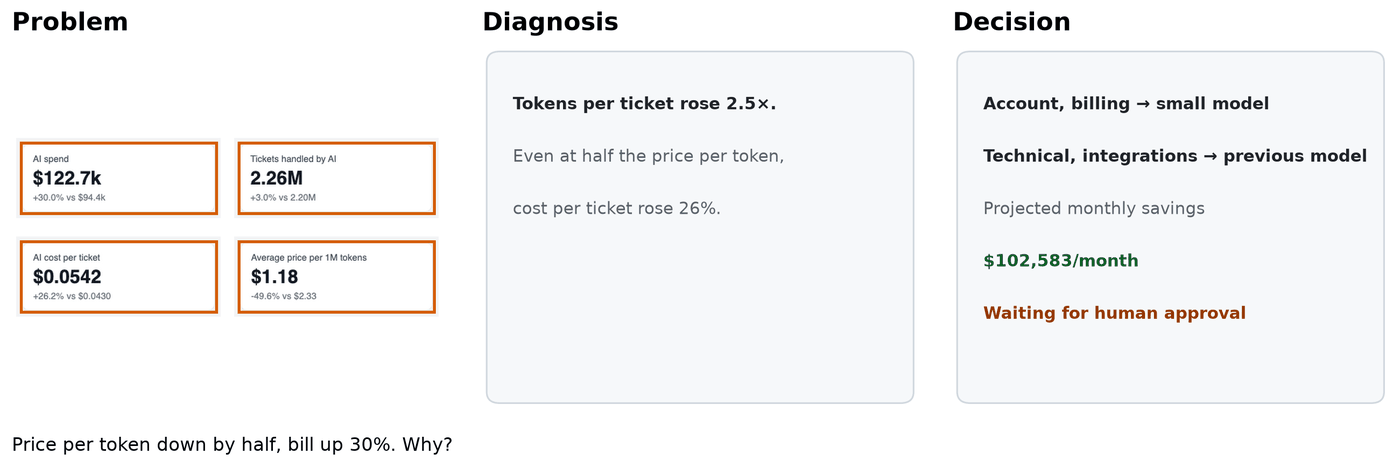

*The company, data, and documents are synthetic yet realistic. By default, you replay a recording of a live Super VL run, so you can follow every step without an endpoint. We chose the recording from several live
runs of the same problem: it had to find the cause and file a valid proposal without reminders from the loop, and among
those we kept one with a typical run time. Its slips are left in, and we point them out.*

## Run this notebook

There are two ways to run it, and one line in the setup cell switches between them.

| | Replay (default) | Live |
|---|---|---|
| What runs | The recording of a real Super VL investigation | Super VL investigates from scratch through the NVIDIA Build API |
| You need | Python 3.12 | Python 3.12, an NVIDIA Build API key, Chrome or Chromium, and macOS or Linux |
| Time | Under a minute | A few minutes |

<details style="margin-bottom: 0.5em">
<summary style="margin-bottom: 0.5em"><b>Get the code</b> and open this notebook from the cloned folder, not on its own</summary>

The notebook needs the rest of its folder: the agent's code, the recording, and the synthetic data. From a terminal (if you
don't have `uv`, install it with `pip install uv`):

```bash
git clone https://github.com/NVIDIA-NeMo/Nemotron.git
cd Nemotron/usage-cookbook/Nemotron-3.5-Super-VL/visual-investigation-agent
uv venv --python 3.12 && source .venv/bin/activate
uv pip install -r requirements.txt
jupyter lab visual_investigation_agent.ipynb
```

In VS Code or Cursor, pick the `.venv` environment as the notebook's kernel. We haven't tested Windows; there, activate the
environment with `.venv\Scripts\activate`.

</details>

**To replay**, run all cells (in JupyterLab, *Run* > *Run All Cells*). The setup cell shows a *Replay mode* card, and every
result card below carries a gray **Replay · recorded run** badge. You don't need a GPU, an API key, or Chrome.

<details style="margin-bottom: 0.5em">
<summary style="margin-bottom: 0.5em"><b>To run live</b> with your own API key</summary>

1. Get an API key from [NVIDIA Build settings](https://build.nvidia.com/settings).
2. Copy `.env.example` to `.env`. The file already sets
   `MODEL_BASE_URL=https://integrate.api.nvidia.com/v1` and
   `MODEL_NAME=nvidia/nemotron-3.5-super-vl-120b-a12b`
   ([model page](https://build.nvidia.com/nvidia/nemotron-3.5-super-vl-120b-a12b));
   paste your key after `NVIDIA_API_KEY=`.
3. Install Chrome or Chromium, which renders the dashboard and document images the agent works with. If it's installed
   somewhere unusual, set `CHROME_PATH` in `.env`.
4. In the setup cell, change `RUN_LIVE = False` to `RUN_LIVE = True`, then run all cells.

You can also download the checkpoint from Hugging Face and serve it from your own OpenAI-compatible vLLM endpoint.

Before Super VL starts, the setup cell checks that this machine can sandbox the agent's Python (built into macOS; on Linux,
install bubblewrap) and that the endpoint handles text, thinking, images, and tool calls. If either check fails, it stops
and says why. The cards below then show your run with a green **Live run** badge, and the run is saved under `runs/`. For
common errors, see the README's Troubleshooting section.

No two runs are identical. The notes between the cards describe the recording, so a live run will word things differently
and can occasionally reach a different conclusion.

</details>

In [1]:
# SPDX-FileCopyrightText: Copyright (c) 2026 NVIDIA CORPORATION & AFFILIATES. All rights reserved.
# SPDX-License-Identifier: Apache-2.0

from dotenv import load_dotenv
from investigator import (load_recording, run_live, show_agent_view, show_build_guide, show_missing_evidence,
                          show_reasoned_decision, show_request, show_setup, show_visual_triage)

load_dotenv()  # reads your endpoint settings from .env; replay doesn't need them

RUN_LIVE = False  # False: replay the recording. True: run Super VL on your endpoint.
SCENARIO = "model-switch-visual"

run = run_live(SCENARIO) if RUN_LIVE else load_recording(SCENARIO)
show_setup(RUN_LIVE, SCENARIO, run)

[Replay mode]

## The problem Super VL is given

Fernledger, a fictional company, runs an AI help desk for four kinds of tickets: account and password, billing, technical
troubleshooting, and integrations. Its models are billed per token, and the AI bill for September 1–21 is 30% higher than for
the same days of August.

Here's what Super VL isn't told: between September 8 and 10, the team moved the help desk from Vesk 4 to Osric 2 Thinking, a
reasoning model with much lower prices per token. Three other models are available: Vesk 4 Lite and Dunlin-3-8B-Instruct
(smaller and cheaper) and Vesk 4 Pro (larger and pricier). Like the company, all five models are fictional.

The team measures quality by resolution rate, the share of tickets that need no human follow-up, and tests every model
offline on past tickets. So in the request, "without hurting quality" means the policy's bar: for each ticket type, no more
than 2 points below Vesk 4.

The next card shows everything Super VL starts with. None of it names the cause. The three moments below follow its 8-step
run, from the first look at the screenshot to the proposal.

[The request]
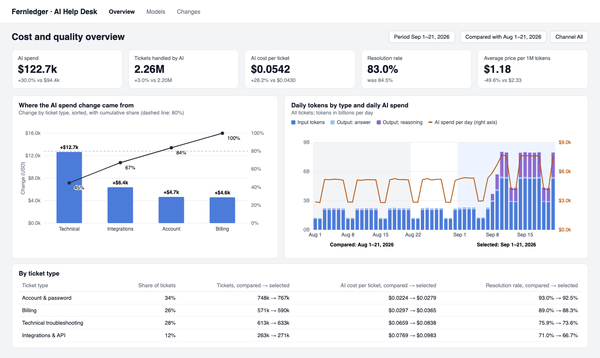

In [2]:
show_request(SCENARIO, RUN_LIVE, run)

## Moment 1 · Read the dashboard

Let's start where Super VL starts: with the screenshot. The next card follows its first step in the order things happened:
what it has, what it sees, what it says, and the tool calls it makes next.

[1 · Read the dashboard]
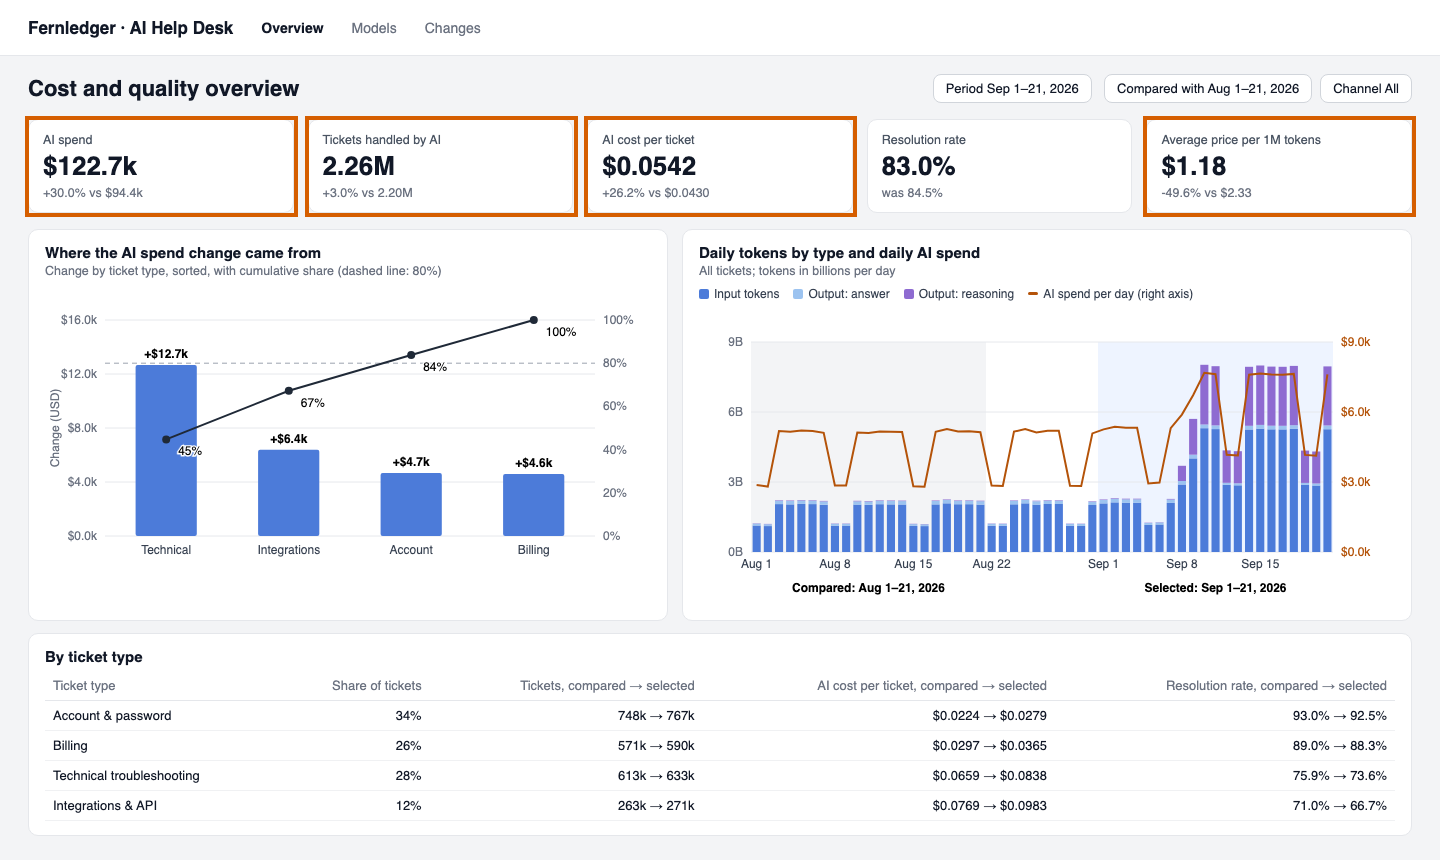

In [3]:
show_visual_triage(run)

The quotation above is Super VL's first note, written before it calls a tool:

> “The dashboard shows AI spend rose 30% ($94.4k → $122.7k) for Sep 1–21 vs Aug 1–21 while tickets rose only 3% and the
> price per 1M tokens fell ~50%, so the driver is a sharp rise in tokens per ticket (usage), concentrated in Technical
> troubleshooting and Integrations & API, with resolution rates also slipping. I'll first reconcile the KPI totals in SQL,
> list the dashboards/documents, and inspect the change log to find when the move started.”

Our explanation: from the screenshot, Super VL formed a hypothesis that higher token use, not volume or token price, drove
the increase. Its change-log query then found the Sep 8–10 Vesk 4 → Osric rollout, which none of its inputs had named.

The instruction to write a first note before any tool call is part of the agent's contract. It makes Super VL's reading of
the image visible and checkable before it sees the database or change log.

## Moment 2 · Find the missing evidence

The dashboard shows the symptom, but it can't price a fix. For that, Super VL needs each model's exact prices, which appear
only on a scanned price list, and each model's quality and token use for every ticket type, which are in the two-page
evaluation report. The playbook names those documents. Which pages to open, and which numbers to pull out, is up to
Super VL.

[2 · Find the missing evidence]
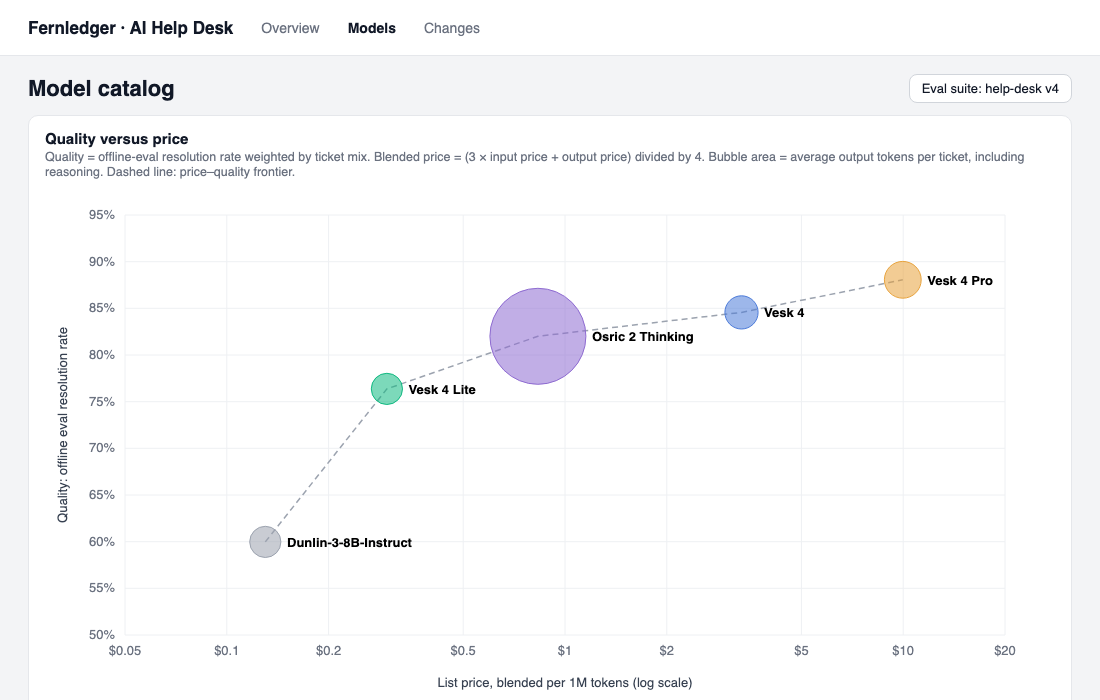
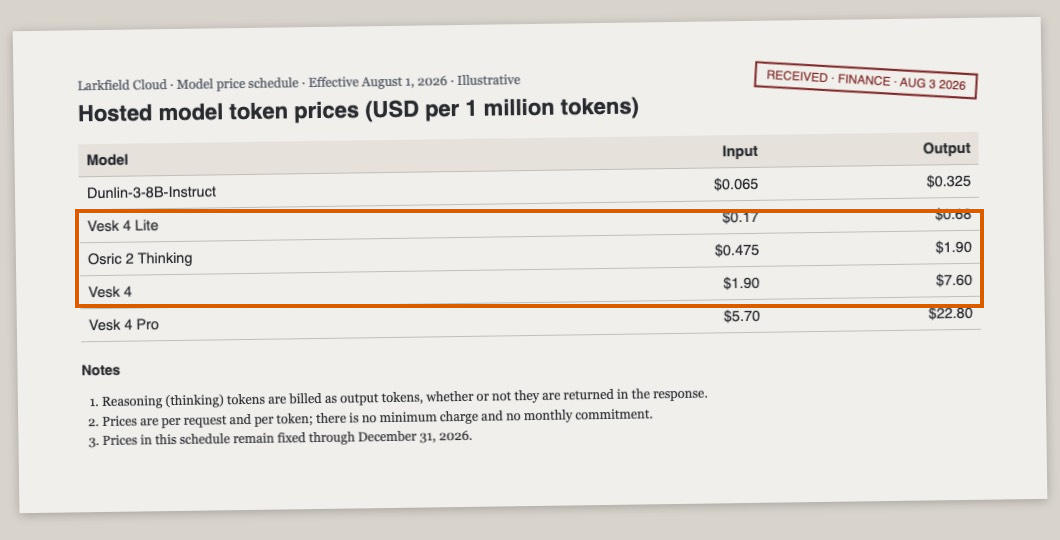
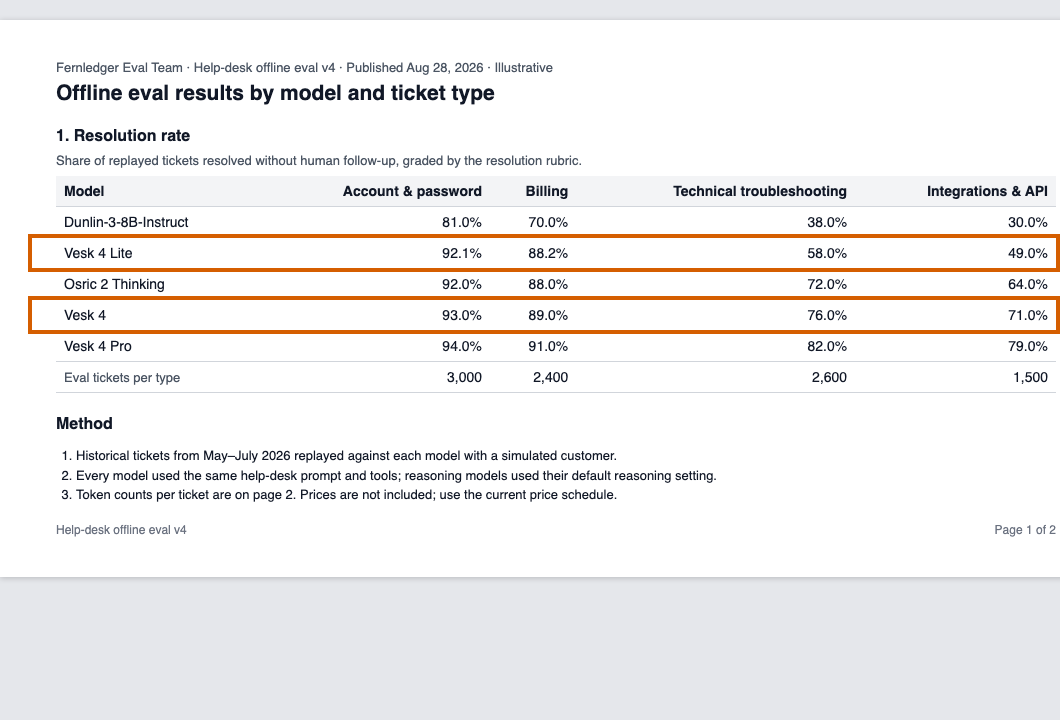
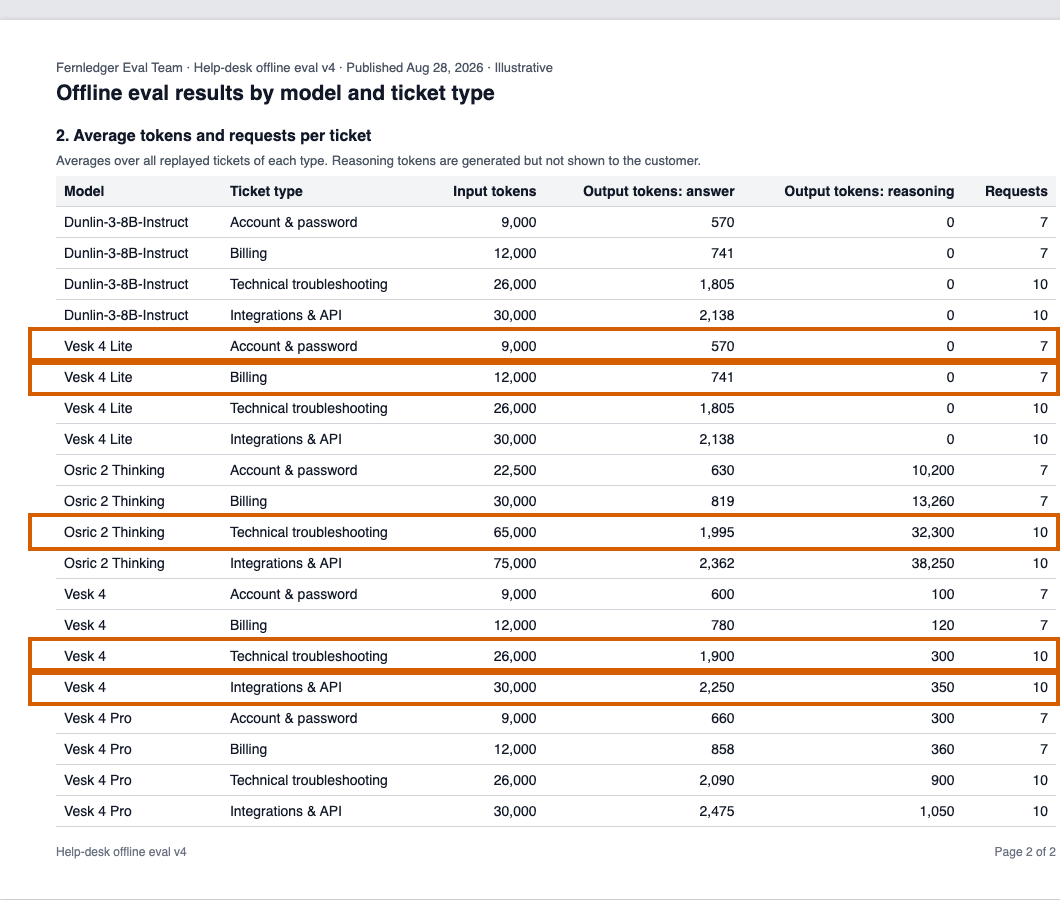

In [4]:
show_missing_evidence(run)

**Our takeaway from the trace:** As its instructions require, Super VL takes no exact numbers from chart pixels. Where to
look instead is its own choice: it opens the source documents, follows the report from page 1 to page 2, and reruns a query
when the date ranges are wrong. The key evidence is simple: the cheaper thinking model uses
over 100 times more reasoning tokens on a technical ticket, so its much higher token use outweighs its lower prices.

## Moment 3 · Decide

Now Super VL has to turn the diagnosis into a proposal. The next card follows the decision in order: what it has, what it
does next, what it says, and what happens next. The exact route table, projected savings, math, evidence, and report checks
are folded below for readers who want to inspect them.

[3 · Decide]
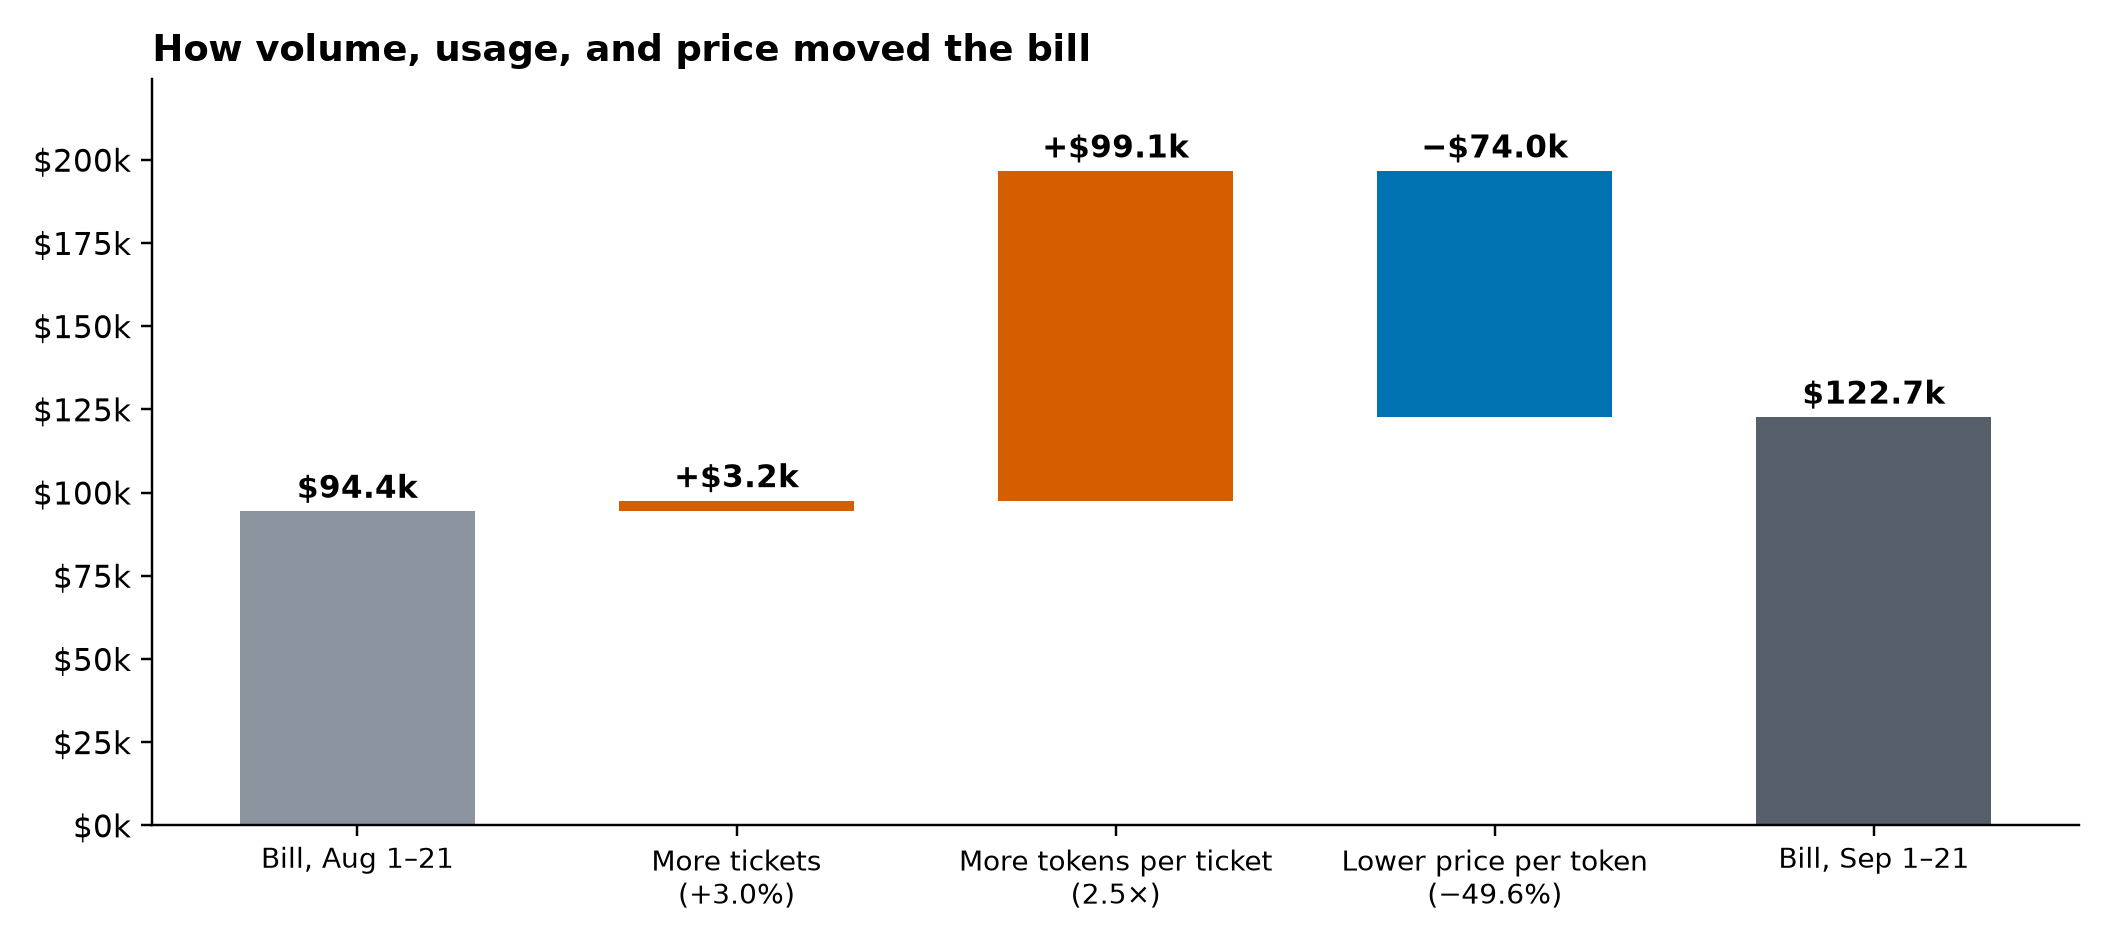

In [5]:
show_reasoned_decision(run)

**Our takeaway from the trace:** Super VL turned a screenshot, the help-desk data, a scanned price list, and a two-page
evaluation report into one proposal a person can approve: for each ticket type, the cheapest model that meets the team's
quality bar. When we recompute it from the source data, all four routes pass and the projected saving holds: about
$103,000 a month, with cost per ticket falling from about 6 cents to about 3. The report's prose has two small slips (see
*Check the report against the data*); they don't affect the proposal, which Super VL calculated in code before writing
the report.

## How the agent works

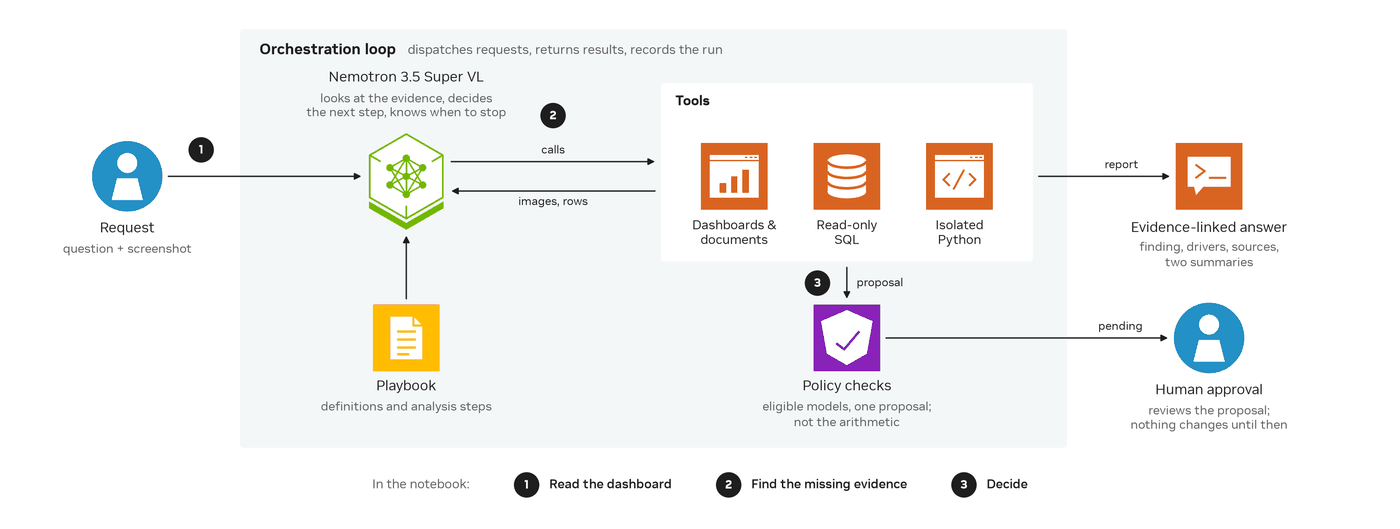

The agent has five parts:

- **The loop** (`investigator/harness.py`) sends the conversation to Super VL, runs the tools it calls, and sends back the
  results. When a tool returns an image, the loop attaches it to the next message; each request holds at most four images,
  so the oldest ones are cleared. The loop stops when Super VL submits its report.
- **The tools** (`investigator/tools.py`) are deliberately narrow. Dashboards and scanned documents come back as images, SQL
  is read-only, Python runs in a sandbox with no network access, and `propose_change` only records a proposal. Most tools
  require a one-sentence `why`; that's what the cards quote as "Why it opened this."
- **The playbook** (`playbook/helpdesk.md`) is plain Markdown: the team's metric definitions and how they investigate a cost
  change. It tells Super VL how to investigate, not what happened.
- **The policy** (`policy/helpdesk.json`) holds the rules the tools enforce: the quality bar, one proposal per run, and a
  plain-language summary for managers.
- **The contract** (`investigator/contract.py`) assembles the system prompt from the playbook and the policy, adds the
  routing objective (the cheapest model that meets the bar), and defines the report. The report is itself a tool call,
  `submit_report`; if it fails a check, the loop sends it back with the reason.

You can change the playbook and the policy without touching any code. Super VL decides what to look at and what to compute,
ordinary code carries out each request and enforces the rules, and a person makes the final call.

The next cell shows that loop in action: the whole run as a conversation, step by step, with every note Super VL wrote and
every tool call it made. Click any call to see what came back. After you run the cell, click *▶ Play the run* to watch the
steps arrive in order, sped up.

[The full run]
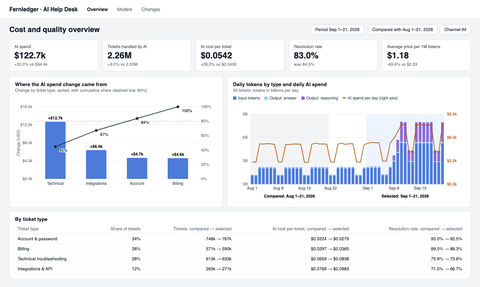
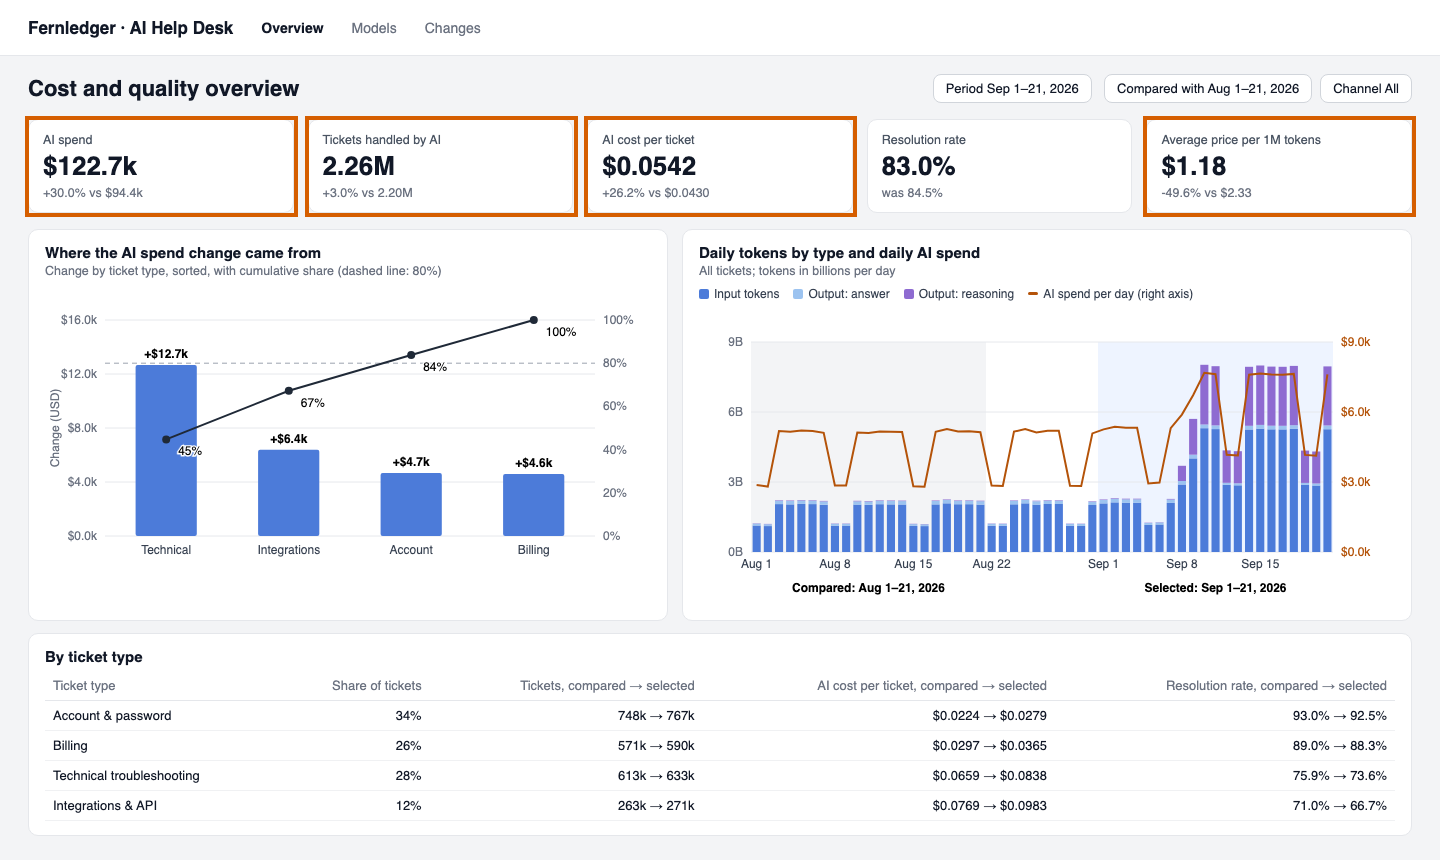
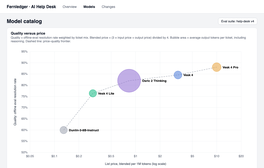
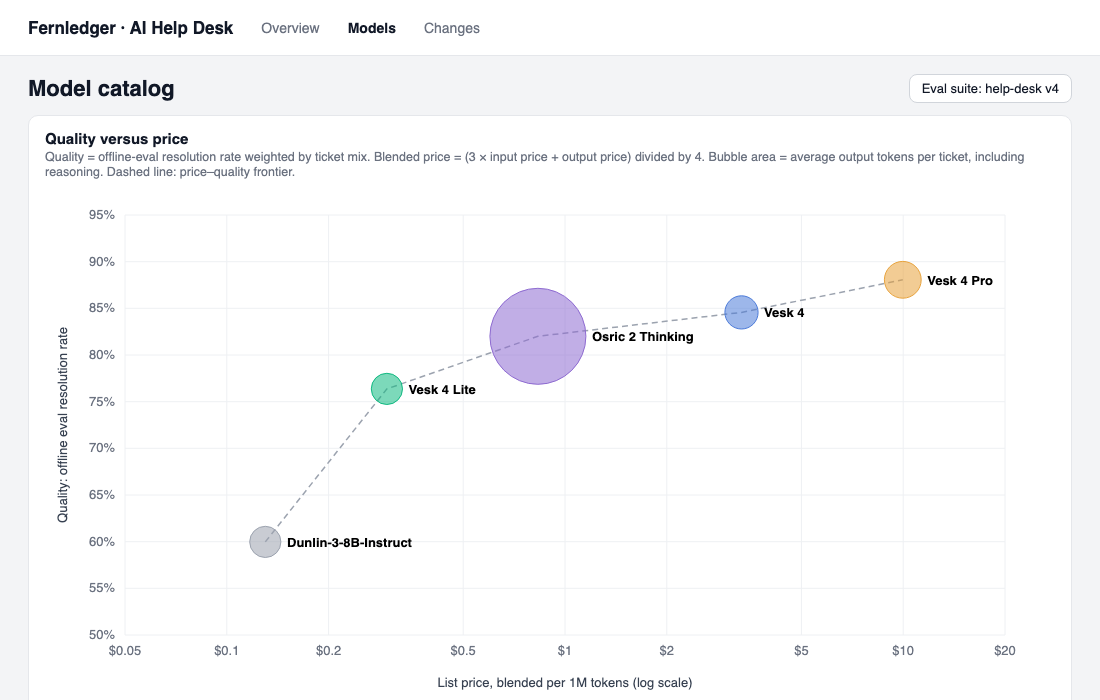
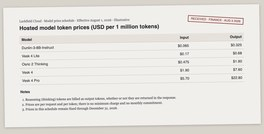
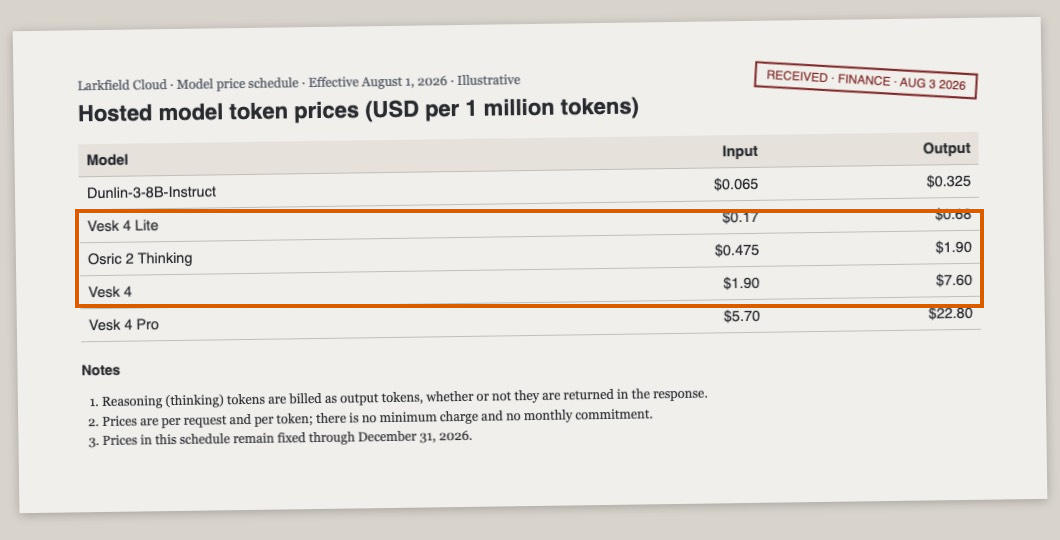
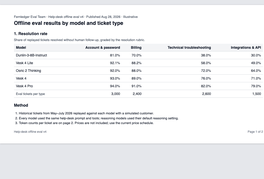
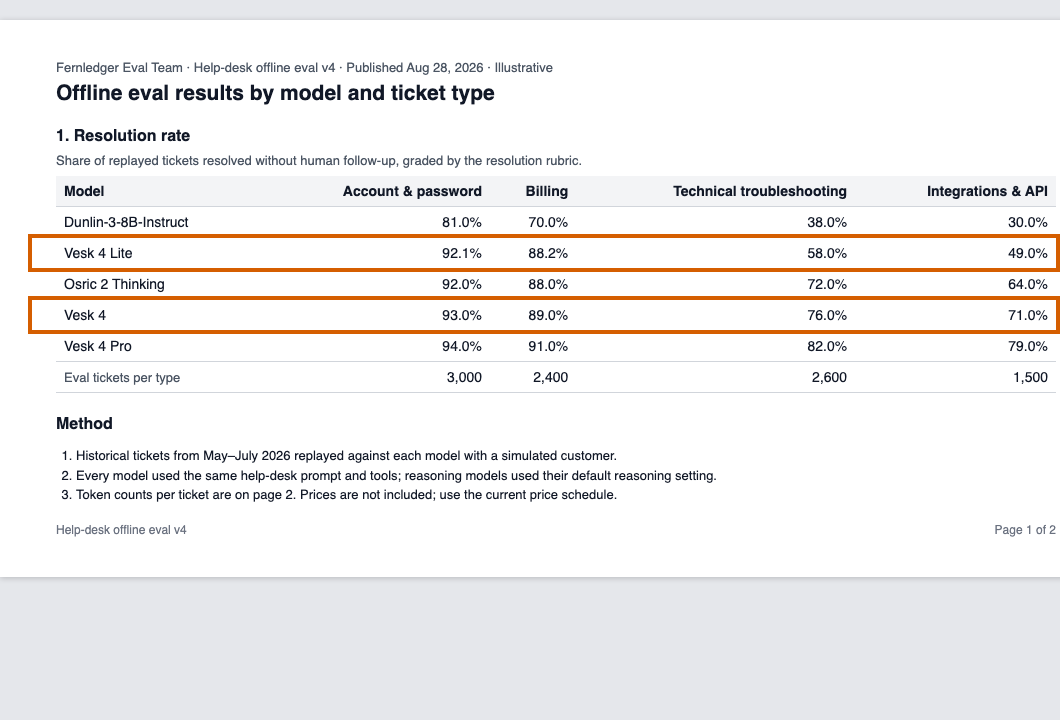
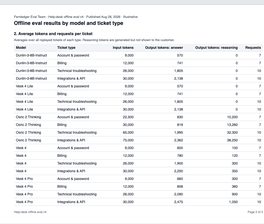
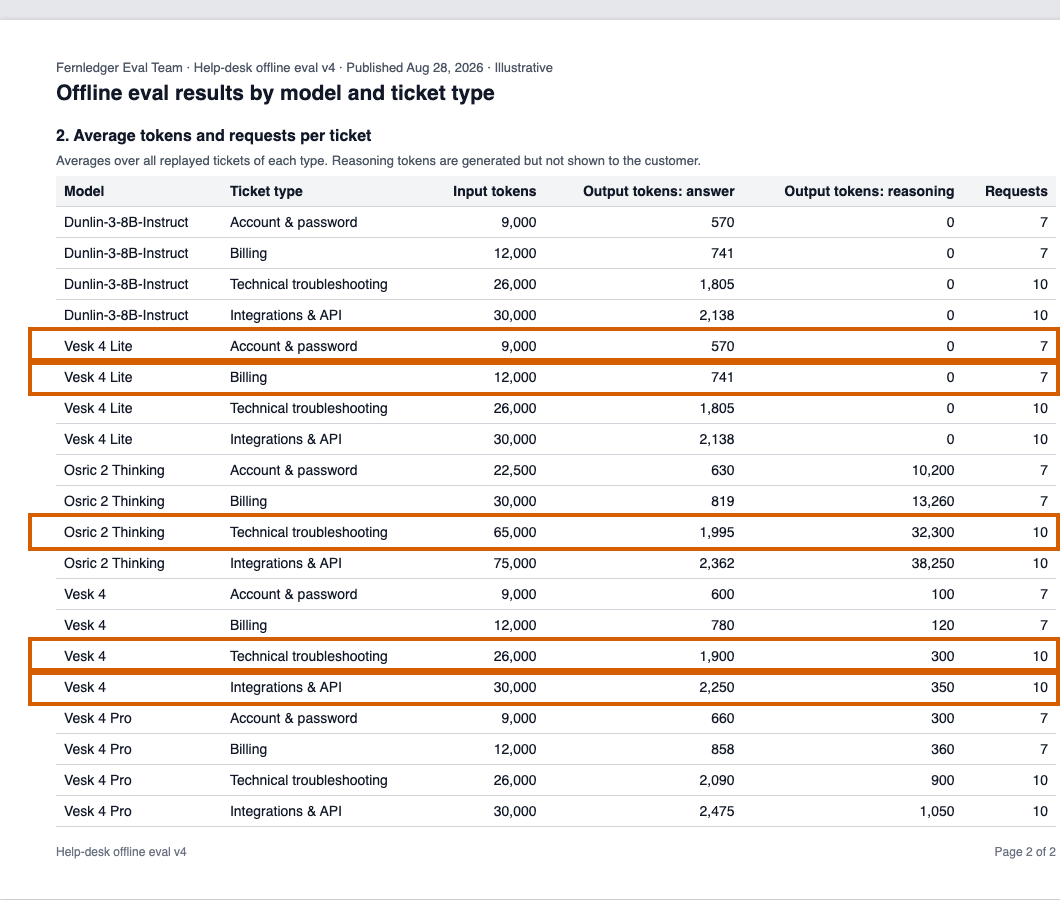

In [6]:
show_agent_view(run)

## Look inside the implementation

When you want to see exactly what Super VL was given, the next cell has all of it: the loop's source code, every tool's
schema, the exact system prompt and request, and the run's settings.

In [7]:
show_build_guide(run)

Tool,What it does
list_dashboards,"List the team's dashboards, their tabs, and each tab's parameters."
render_dashboard,"Render one dashboard tab as an image, like a BI tool's render or export API."
list_documents,List the team's documents.
view_document,Open one page of a document.
run_sql,Run one read-only SQLite query against the help-desk database.
run_python,Run Python 3 (standard library only) in a sandbox with no network.
propose_change,File one routing change for human review.
submit_report,Submit the final report.


## Make it yours

To point the agent at your own problem:

1. **Swap in your systems.** `world/` stands in for five things the agent uses: dashboard tabs it can render as images,
   documents it can open page by page, a read-only SQLite database, the model catalog with offline quality rates (for the
   policy), and the scenario's names and dates (for the prompt). Replace each with your own; `investigator/tools.py`,
   `harness.py`, `policy.py`, `contract.py`, and `sandbox.py` are where they're read.
2. **Rewrite the playbook and policy** for your metrics, tables, and rules. The playbook says how to investigate; the policy
   says what a proposal has to meet. If your quality bar is an average, also check it for each group of customers you
   serve, such as each language or region.
3. **Keep the loop, and test it.** Run it several times on cases where you already know the answer before you rely on it.
4. **Keep a person in charge.** Keep data access read-only and every change a proposal that a person approves.
   Before you give the agent a tool that changes anything, give it a way to stop and ask a person.

## Recap

You followed Super VL through a complete investigation. In this example, it:

- **Read a dashboard screenshot**, put the numbers together into a theory, and wrote the queries to test it.
- **Found what the dashboard couldn't show**, opening a scanned price list, choosing pages in a two-page report, and reading
  exact numbers from them.
- **Recommended a fix a person can approve**: the cheapest model for each ticket type that meets the quality bar, filed as
  one proposal for review.

**What to take away for your own agents:**

- **Give the model the evidence as images.** Super VL read the dashboard, a scanned price list, and report pages directly.
  Nothing had to be converted to text first.
- **Give it a playbook and narrow tools, not answers.** The playbook says how the team investigates, and each tool does one
  safe thing. Super VL found the cause and priced the fix itself.
- **Ask it to show its reading, keep a person in charge, and check the numbers.** Its first note made its reading of the
  screenshot checkable, the agent can only propose, and checking its figures after the run caught two slips in the
  report's wording.

## Related Nemotron resources

- [Nemotron usage cookbook](https://github.com/NVIDIA-NeMo/Nemotron/tree/main/usage-cookbook): more practical model and application examples.
- [NVIDIA Build](https://build.nvidia.com/): hosted model catalog and API access.
- [Nemotron 3.5 Super VL fine-tuning guide](https://docs.nvidia.com/nemo/automodel/model-coverage/omni/nvidia/NVIDIA-Nemotron-3.5-Super-VL-120B-A12B-BF16): customization with NeMo AutoModel.
- [Build a Bash computer-use agent with NVIDIA Nemotron](https://developer.nvidia.com/blog/create-your-own-bash-computer-use-agent-with-nvidia-nemotron-in-one-hour/): another bounded, tool-using agent.